# Day 12: Model Evaluation and Performance Analysis

## Introduction

Model evaluation is an important step in machine learning because it measures how effectively a trained model predicts outcomes on unseen data. Accuracy provides an overall measure of correct predictions, while precision, recall, and F1-score provide additional information about classification performance.

In this task, the Logistic Regression and Decision Tree classifiers developed on Day 11 are evaluated using the Iris dataset. The previously trained models are loaded from pickle files, and their performance is assessed without retraining them.

### Objectives

1. Load the trained classification models from Day 11.
2. Calculate accuracy, precision, recall, and F1-score.
3. Generate and interpret confusion matrices.
4. Compare the performance of both classifiers.
5. Identify suitable evaluation metrics for the Iris classification task.
6. Prepare a performance report based on the actual results.

In [1]:
import pickle
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Paths to the Day 11 files
DAY11_FOLDER = Path("../Day 11")
MODEL_FOLDER = DAY11_FOLDER / "saved_models"
DATA_PATH = DAY11_FOLDER / "Iris.csv"

print("Dataset found:", DATA_PATH.exists())
print("Logistic Regression model found:",
      (MODEL_FOLDER / "logistic_regression.pkl").exists())
print("Decision Tree model found:",
      (MODEL_FOLDER / "decision_tree.pkl").exists())

Dataset found: True
Logistic Regression model found: True
Decision Tree model found: True


## 1. Loading the Trained Models

The `pickle` module is used to deserialize the previously saved model objects. This allows the existing classifiers to be reused in a separate notebook without calling `fit()` again.

The Logistic Regression and Decision Tree models retain the parameters and learned information stored in their respective pickle files.

In [2]:
# Load the existing Logistic Regression model
with open(MODEL_FOLDER / "logistic_regression.pkl", "rb") as file:
    logistic_model = pickle.load(file)

# Load the existing Decision Tree model
with open(MODEL_FOLDER / "decision_tree.pkl", "rb") as file:
    decision_tree_model = pickle.load(file)

print("Both saved models loaded successfully.")
print("Logistic Regression:", type(logistic_model).__name__)
print("Decision Tree:", type(decision_tree_model).__name__)

Both saved models loaded successfully.
Logistic Regression: LogisticRegression
Decision Tree: DecisionTreeClassifier


## 2. Preparing the Test Dataset

The Iris dataset is loaded to recreate the same test split used during Day 11. The flower measurements are used as input features, and the Species column is used as the target.

The same data preparation and train-test split settings used during model training must be maintained for a fair evaluation.

In [3]:
# Load the original Iris dataset
data = pd.read_csv(DATA_PATH)

# Apply the same preprocessing as Day 11
df = data.drop(columns=["Id"], errors="ignore")
df = df.drop_duplicates()

# Select the same features and target
feature_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[feature_columns]
y = df["Species"]

# Reproduce the original Day 11 split
x_train, x_test, y_train, y_test = train_test_split(
    X.values,
    y,
    test_size=0.2,
    random_state=2
)

print("Cleaned dataset shape:", df.shape)
print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("\nTest samples per species:")
print(y_test.value_counts())

Cleaned dataset shape: (147, 5)
Training samples: 117
Testing samples: 30

Test samples per species:
Species
Iris-versicolor    11
Iris-setosa        11
Iris-virginica      8
Name: count, dtype: int64


## 3. Generating Predictions

The saved models predict the species of the flowers in the test dataset. These predictions are compared with the actual species to evaluate model performance.

In [4]:
# Predict on the entire test dataset using both saved models
y_pred_lr = logistic_model.predict(x_test)
y_pred_dt = decision_tree_model.predict(x_test)

# Select two samples for demonstration
sample_data = x_test[:2]
actual_species = y_test.iloc[:2]

# Display the demonstration results
for i in range(len(sample_data)):
    print(f"\nSample {i + 1}")
    print("Input Data:")
    print(pd.DataFrame([sample_data[i]], columns=["Sepal Length", "Sepal Width", "Petal Length", "Petal Width"]).to_string(index=False))
    print("Actual Species:", actual_species.iloc[i])
    print("Logistic Regression Prediction:", y_pred_lr[i])
    print("Decision Tree Prediction:", y_pred_dt[i])



Sample 1
Input Data:
 Sepal Length  Sepal Width  Petal Length  Petal Width
          5.0          2.3           3.3          1.0
Actual Species: Iris-versicolor
Logistic Regression Prediction: Iris-versicolor
Decision Tree Prediction: Iris-versicolor

Sample 2
Input Data:
 Sepal Length  Sepal Width  Petal Length  Petal Width
          7.2          3.0           5.8          1.6
Actual Species: Iris-virginica
Logistic Regression Prediction: Iris-virginica
Decision Tree Prediction: Iris-versicolor


## 4. Evaluating Model Performance

Four evaluation metrics are used to assess the classifiers:

- **Accuracy:** The proportion of all test samples classified correctly.
- **Precision:** The proportion of positive predictions for a class that are correct.
- **Recall:** The proportion of actual samples of a class that are correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

Because the Iris dataset contains three classes, precision, recall, and F1-score are reported for individual classes as well as using macro and weighted averaging. **Macro averaging** calculates the unweighted average across all classes, giving equal importance to each species. **Weighted averaging** accounts for the number of actual test samples in each class.

For comparing the two models, accuracy and macro F1-score are used. This allows overall correctness to be assessed alongside performance across all three species, with each species contributing equally to the macro F1-score.

## 4.1 Classification Reports

The classification report summarizes precision, recall, F1-score, and support for each flower species. These metrics help assess how well each model classifies individual species.

In [5]:
# Get the classification reports as dictionaries
lr_report = classification_report(
    y_test, y_pred_lr, output_dict=True, zero_division=0
)

dt_report = classification_report(
    y_test, y_pred_dt, output_dict=True, zero_division=0
)

# Display the complete performance reports
print("Logistic Regression Performance:\n")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nDecision Tree Performance:\n")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Logistic Regression Performance:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        11
Iris-versicolor       1.00      1.00      1.00        11
 Iris-virginica       1.00      1.00      1.00         8

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30


Decision Tree Performance:

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        11
Iris-versicolor       0.92      1.00      0.96        11
 Iris-virginica       1.00      0.88      0.93         8

       accuracy                           0.97        30
      macro avg       0.97      0.96      0.96        30
   weighted avg       0.97      0.97      0.97        30



## 4.2 Confusion Matrices

A confusion matrix compares the actual flower species with the species predicted by a model. It shows correct classifications and the cases where the model confused one species with another.

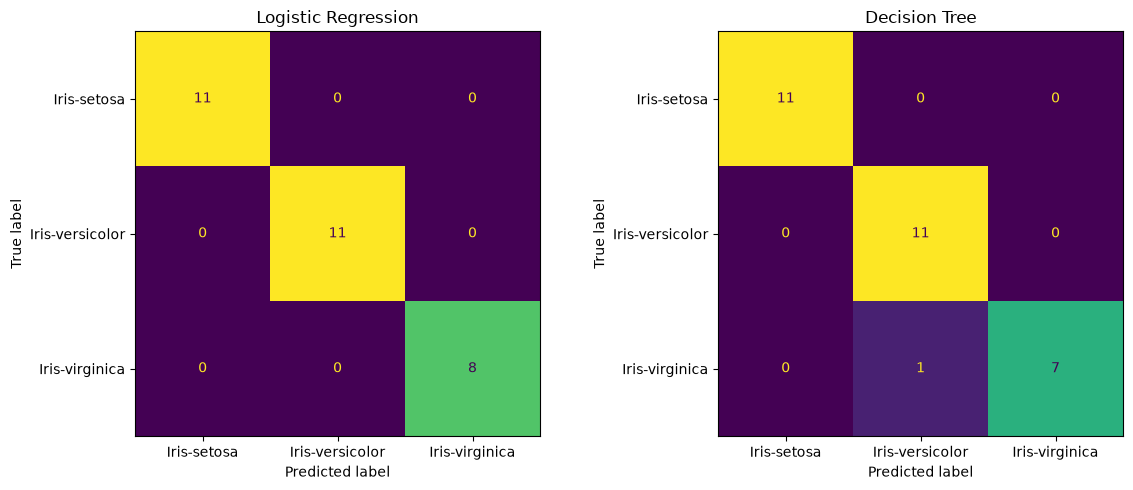

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()

### 5. Model Performance Comparison

The performance of Logistic Regression and Decision Tree is compared using multiple evaluation metrics to understand how effectively each model classifies the Iris species.

The following metrics are used:

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision (Macro):** Measures how reliably the model predicts each species, giving equal importance to every species.
- **Recall (Macro):** Measures how effectively the model identifies the actual instances of each species, giving equal importance to every species.
- **F1-Score (Macro):** Combines precision and recall while treating all species equally.
- **F1-Score (Weighted):** Combines precision and recall while accounting for the number of actual samples in each species.
- **Balanced Accuracy:** Calculates the average recall across the species, helping evaluate performance when classes have different numbers of samples.

Comparing these metrics provides a more comprehensive assessment than accuracy alone. The results help identify which model performs more consistently across the three Iris species.

In [7]:
# Compare both models using multiple evaluation metrics
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt
}

comparison = {}

for model_name, predictions in models.items():
    comparison[model_name] = {
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100,
        "Balanced Accuracy (%)": balanced_accuracy_score(y_test, predictions) * 100,
        "Precision (Macro %)": precision_score(
            y_test, predictions, average="macro"
        ) * 100,
        "Recall (Macro %)": recall_score(
            y_test, predictions, average="macro"
        ) * 100,
        "F1-Score (Macro %)": f1_score(
            y_test, predictions, average="macro"
        ) * 100,
        "F1-Score (Weighted %)": f1_score(
            y_test, predictions, average="weighted"
        ) * 100
    }

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(2))

,Logistic Regression,Decision Tree
Accuracy (%),100.0,96.67
Balanced Accuracy (%),100.0,95.83
Precision (Macro %),100.0,97.22
Recall (Macro %),100.0,95.83
F1-Score (Macro %),100.0,96.33
F1-Score (Weighted %),100.0,96.63


## 6. Saving the Evaluation Results

The classification reports, confusion matrices, and model comparison results are saved to a text file so they can be reviewed later without rerunning the evaluation.

In [8]:
# Create the model comparison summary
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy (%)": [
        round(accuracy_score(y_test, y_pred_lr) * 100, 2),
        round(accuracy_score(y_test, y_pred_dt) * 100, 2)
    ],
    "Precision (Macro %)": [
        round(precision_score(y_test, y_pred_lr, average="macro") * 100, 2),
        round(precision_score(y_test, y_pred_dt, average="macro") * 100, 2)
    ],
    "Recall (Macro %)": [
        round(recall_score(y_test, y_pred_lr, average="macro") * 100, 2),
        round(recall_score(y_test, y_pred_dt, average="macro") * 100, 2)
    ],
    "F1-Score (Macro %)": [
        round(f1_score(y_test, y_pred_lr, average="macro") * 100, 2),
        round(f1_score(y_test, y_pred_dt, average="macro") * 100, 2)
    ]
})

# Compute confusion matrices for both models
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Create a text file containing the evaluation results
report_path = Path("performance_report.txt")

with open(report_path, "w", encoding="utf-8") as file:
    file.write("DAY 12: MODEL EVALUATION\n\n")

    file.write("LOGISTIC REGRESSION\n")
    file.write(
        classification_report(y_test, y_pred_lr, zero_division=0)
    )
    file.write("\nConfusion Matrix:\n")
    file.write(str(cm_lr))

    file.write("\n\n\nDECISION TREE\n")
    file.write(
        classification_report(y_test, y_pred_dt, zero_division=0)
    )
    file.write("\nConfusion Matrix:\n")
    file.write(str(cm_dt))

    file.write("\n\n\nMODEL COMPARISON\n")
    file.write(results.to_string(index=False))

print("Report saved to:", report_path.resolve())


Report saved to: E:\OneDrive - Indian Oil Corporation Limited\Desktop\AI-ML-Internship\Day 12\performance_report.txt



## 7. Conclusion

Both saved models were evaluated on 30 test samples from the Iris dataset. Logistic Regression achieved **100% accuracy and a 1.00 macro F1-score**, correctly classifying all samples across Iris-setosa, Iris-versicolor, and Iris-virginica. Its precision, recall, and F1-score were 1.00 for all three species.

The Decision Tree model achieved **96.67% accuracy and a macro F1-score of approximately 0.96**. It classified all Iris-setosa and Iris-versicolor samples correctly in terms of recall, but its recall for Iris-virginica was 0.88, indicating that it missed some actual Iris-virginica samples. Its precision for Iris-versicolor was also lower at 0.92.

Therefore, **Logistic Regression performed better than Decision Tree on this test split**, with perfect classification results compared with the Decision Tree's one or more classification errors. These results show that Logistic Regression was the stronger performer for this particular evaluation; testing on additional unseen data would be needed to determine whether this advantage generalizes.
